In [35]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

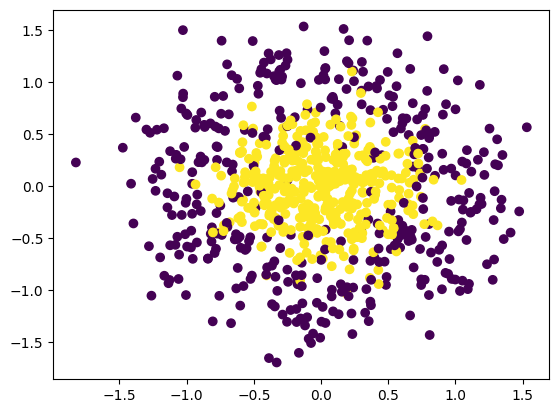

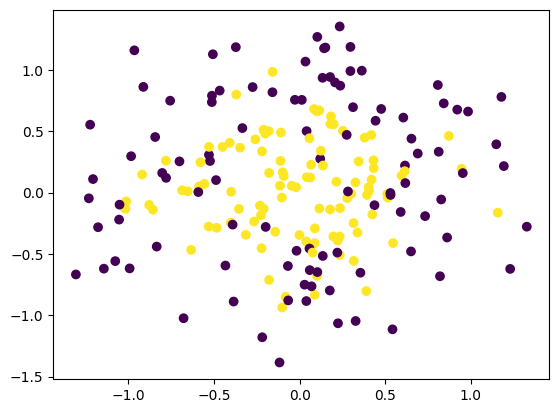

In [72]:
X, y = make_circles(n_samples=1000, noise=0.3, factor = 0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
plt.scatter(X_train[:,0], X_train[:,1], c=y_train)
plt.show()
plt.scatter(X_test[:,0], X_test[:,1], c=y_test)
plt.show()

In [73]:
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(device)

cuda


In [74]:
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train, dtype=torch.float32).to(device).view(-1,1)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test = torch.tensor(y_test, dtype=torch.float32).to(device).view(-1,1)

In [75]:
class chuva(nn.Module):
    def __init__(self, hidden = 3):
        super().__init__()
        self.hidden = hidden
        self.layer1 = nn.Linear(2, hidden)
        self.layer2 = nn.Linear(hidden, 1)
    def forward(self, x):
        z = self.layer1(x)
        fz = torch.sigmoid(z)
        res = self.layer2(fz)
        return res


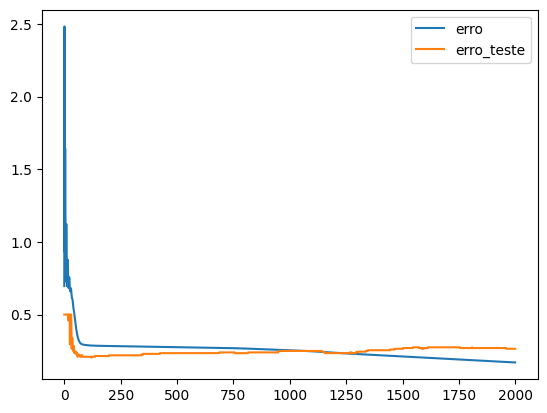

In [76]:
dandan = chuva(hidden = 100)
dandan.to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(dandan.parameters(), lr=0.1)
epochs = 2000
erro = []
erro_teste = []
for i in range(epochs):
    optimizer.zero_grad()
    preds = dandan.forward(X_train)
    loss = criterion(preds, y_train)
    loss.backward()
    optimizer.step()
    erro.append(loss.item())
    with torch.no_grad():
        preds = dandan.forward(X_test)
        preds = torch.sigmoid(preds)
        preds = (preds > 0.5).float()
        acc = accuracy_score(y_test.cpu(), preds.cpu())
    erro_teste.append(1-acc)
plt.plot(erro)
plt.plot(erro_teste)
plt.legend(['erro', 'erro_teste'])
plt.show()

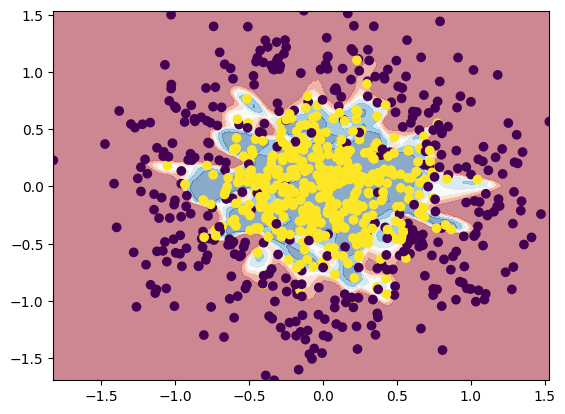

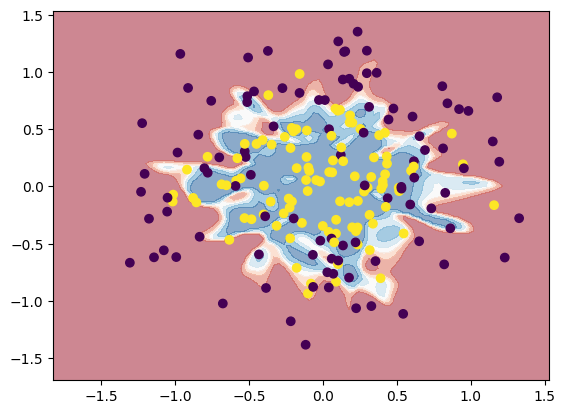

In [77]:
xx, yy = np.meshgrid(np.linspace(X[:,0].min(),X[:,0].max(), 100), np.linspace(X[:,1].min(),X[:,1].max(), 100))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32).to(device)
with torch.no_grad():
    preds = dandan.forward(grid)
    preds = torch.sigmoid(preds)
    preds = preds.cpu().numpy()
    preds = preds.reshape(xx.shape)
plt.contourf(xx, yy, preds, cmap='RdBu', alpha=0.5)
plt.scatter(X_train.cpu()[:,0], X_train.cpu()[:,1], c=y_train.cpu())
plt.show()

xx, yy = np.meshgrid(np.linspace(X[:,0].min(),X[:,0].max(), 100), np.linspace(X[:,1].min(),X[:,1].max(), 100))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32).to(device)
with torch.no_grad():
    preds = dandan.forward(grid)
    preds = torch.sigmoid(preds)
    preds = preds.cpu().numpy()
    preds = preds.reshape(xx.shape)
plt.contourf(xx, yy, preds, cmap='RdBu', alpha=0.5)
plt.scatter(X_test.cpu()[:,0], X_test.cpu()[:,1], c=y_test.cpu())
plt.show()

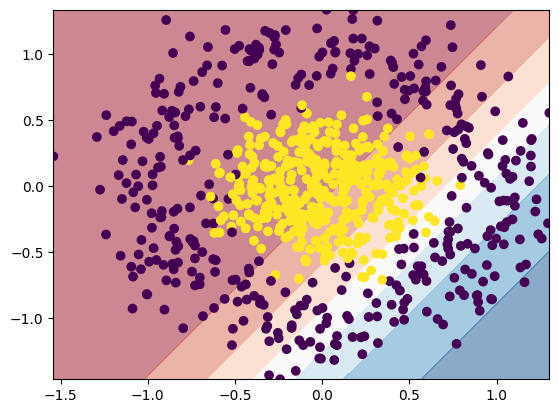

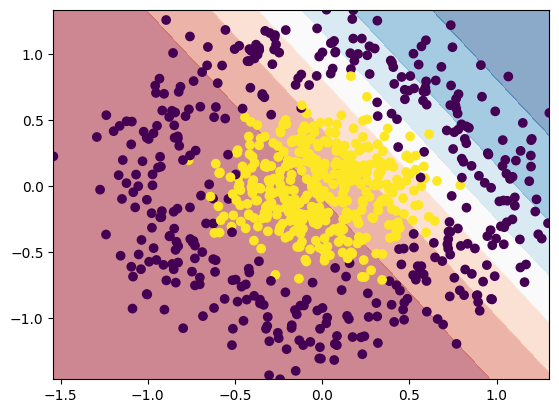

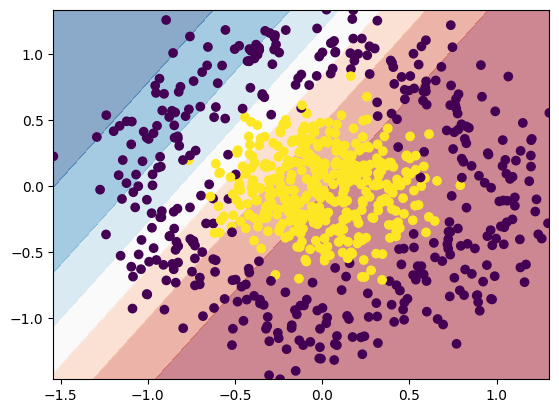

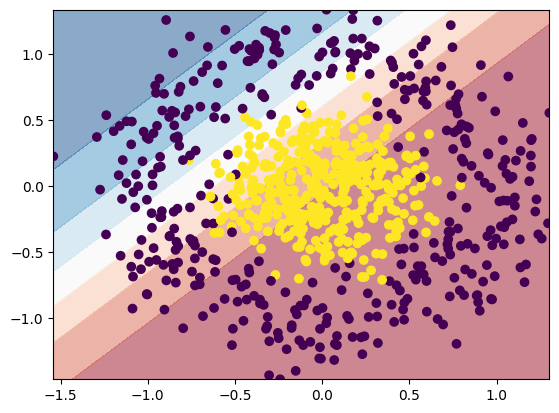

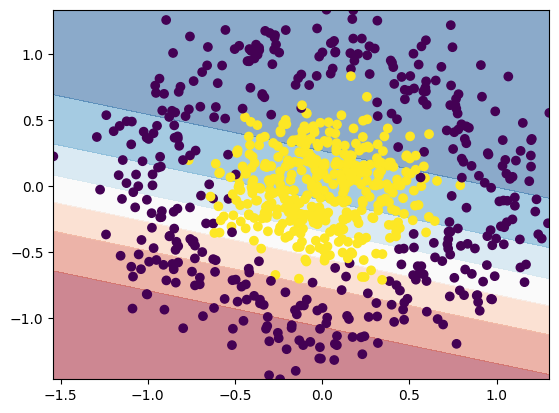

...

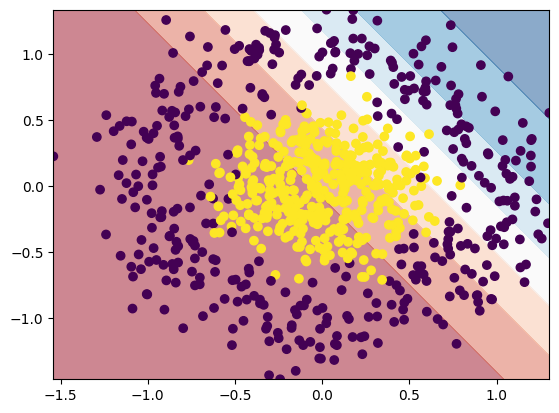

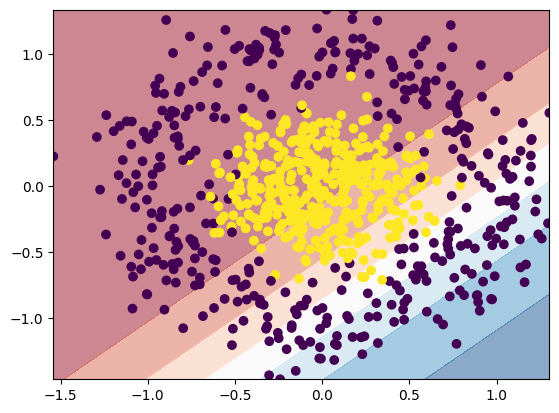

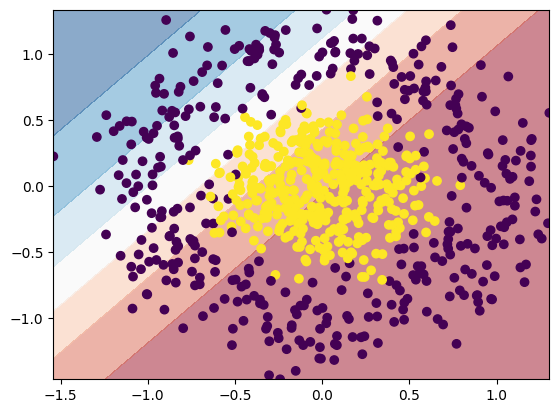

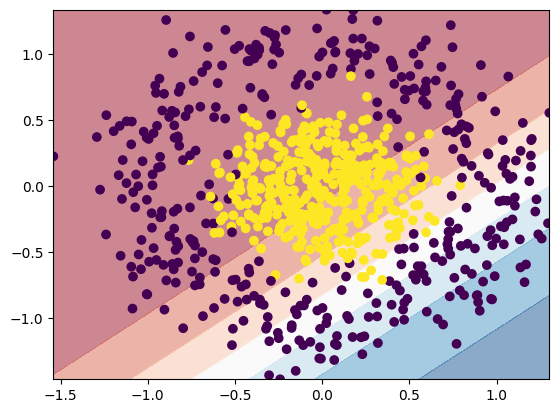

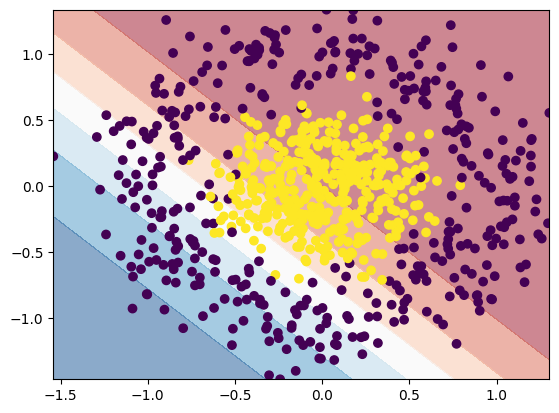

In [59]:
xx, yy = np.meshgrid(np.linspace(X[:,0].min(),X[:,0].max(), 100), np.linspace(X[:,1].min(),X[:,1].max(), 100))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32).to(device)
for i in range(dandan.hidden):
  with torch.no_grad():
      preds = dandan.layer1(grid)[:,i]
      preds = torch.sigmoid(preds)
      preds = preds.cpu().numpy()
      preds = preds.reshape(xx.shape)
  plt.contourf(xx, yy, preds, cmap='RdBu', alpha=0.5)
  plt.scatter(X_train.cpu()[:,0], X_train.cpu()[:,1], c=y_train.cpu())
  plt.show()